In [1]:

!pip -q install timm scikit-learn pandas tqdm pillow

from google.colab import drive, files
import os, glob, gc, zipfile, shutil, random
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms.functional as TF
import timm

from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report
)

drive.mount("/content/drive")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

ROOT = "/content/drive/MyDrive/DR_Project"

STAGE1_W = (
    ROOT + "/stage1/weights/"
    "stage1_original_fixed_best_dr_b0.pth"
)

OUT_DIR = ROOT + "/stage3_ablation_B4_without_SE"
os.makedirs(OUT_DIR, exist_ok=True)

NO_SE_CKPT = OUT_DIR + "/stage3_B4_no_SE_best.pth"

assert os.path.isfile(STAGE1_W), (
    "Stage 1 B0 weights not found: " + STAGE1_W
)

print("\nUpload stage3_local.zip")
uploaded = files.upload()

zip_names = [
    name for name in uploaded
    if name.lower().endswith(".zip")
]

assert len(zip_names) == 1, \
    "Please upload exactly one stage3_local.zip file."

with zipfile.ZipFile(zip_names[0], "r") as z:
    z.extractall("/content")

STAGE3_LOCAL = "/content/stage3_local"

assert os.path.isdir(STAGE3_LOCAL), (
    "stage3_local folder not found after extraction."
)

print("Stage 3 data extracted successfully.")
print("Output directory:", OUT_DIR)


Mounted at /content/drive
Device: cuda

Upload stage3_local.zip


Saving stage3_local.zip to stage3_local.zip
Stage 3 data extracted successfully.
Output directory: /content/drive/MyDrive/DR_Project/stage3_ablation_B4_without_SE


In [2]:

# Find Stage 3 CSV
required_columns = {
    "img_path", "label", "stage3_mask_path"
}

csv_files = glob.glob(
    STAGE3_LOCAL + "/**/*.csv",
    recursive=True
)

stage3_csv = None

for path in csv_files:
    columns = set(pd.read_csv(path, nrows=0).columns)
    if required_columns.issubset(columns):
        stage3_csv = path
        break

assert stage3_csv is not None, "Stage 3 CSV not found."

df = pd.read_csv(stage3_csv).copy()

DRIVE_RGB = (
    "/content/drive/MyDrive/"
    "Dataset_extracted/colored_images/colored_images"
)

LOCAL_RGB = "/content/dr_images"
os.makedirs(LOCAL_RGB, exist_ok=True)

# Convert Drive image paths to local paths
def local_path(path):
    path = str(path).strip()

    if path.startswith(DRIVE_RGB + os.sep):
        relative = os.path.relpath(path, DRIVE_RGB)
        return os.path.join(LOCAL_RGB, relative)

    return path

original_paths = df["img_path"].astype(str).tolist()
local_paths = [local_path(p) for p in original_paths]

copy_pairs = list(dict.fromkeys(
    (src, dst)
    for src, dst in zip(original_paths, local_paths)
    if src != dst
))

def copy_image(pair):
    src, dst = pair

    if not os.path.isfile(src):
        raise FileNotFoundError(src)

    os.makedirs(os.path.dirname(dst), exist_ok=True)

    if (
        not os.path.isfile(dst)
        or os.path.getsize(src) != os.path.getsize(dst)
    ):
        shutil.copyfile(src, dst)

print("Copying RGB images:", len(copy_pairs))

with ThreadPoolExecutor(max_workers=8) as pool:
    for _ in tqdm(
        pool.map(copy_image, copy_pairs),
        total=len(copy_pairs)
    ):
        pass

df["img_path"] = local_paths

df["stage3_mask_path"] = (
    df["stage3_mask_path"]
    .fillna("")
    .astype(str)
    .str.strip()
)

df["label"] = df["label"].astype(int)

# Verify all images and masks exist
assert df["img_path"].map(os.path.isfile).all(), \
    "Some RGB images are missing."

assert df["stage3_mask_path"].map(os.path.isfile).all(), \
    "Some refined masks are missing."

df["basename"] = df["img_path"].map(os.path.basename)

assert df["basename"].is_unique, \
    "Duplicate image filenames found."

# Original train, validation, and test splits
SPLIT_DIR = ROOT + "/splits"

def read_split(name):
    path = SPLIT_DIR + f"/stage1_{name}_names.txt"

    with open(path, "r") as f:
        return {
            line.strip()
            for line in f
            if line.strip()
        }

train_names = read_split("train")
val_names = read_split("val")
test_names = read_split("test")

assert not (train_names & val_names)
assert not (train_names & test_names)
assert not (val_names & test_names)

assert set(df["basename"]) == (
    train_names | val_names | test_names
), "Dataset does not exactly match the original splits."

train_df = df[
    df["basename"].isin(train_names)
].copy().reset_index(drop=True)

val_df = df[
    df["basename"].isin(val_names)
].copy().reset_index(drop=True)

test_df = df[
    df["basename"].isin(test_names)
].copy().reset_index(drop=True)

CLASS_NAMES = [
    "no_dr", "mild", "moderate",
    "severe", "proliferative_dr"
]

NUM_CLASSES = 5

# Same training oversampling as Stage 3
train_balanced = pd.concat(
    [
        train_df,
        train_df[train_df.label == 1],
        train_df[train_df.label == 3],
        train_df[train_df.label == 4]
    ],
    ignore_index=True
)

print("Training:", len(train_df))
print("Balanced training:", len(train_balanced))
print("Validation:", len(val_df))
print("Testing:", len(test_df))

print("\nDataset and splits verified.")


Copying RGB images: 35126


  0%|          | 0/35126 [00:00<?, ?it/s]

Training: 24588
Balanced training: 27405
Validation: 5269
Testing: 5269

Dataset and splits verified.


In [3]:

class DRStage3Dataset(Dataset):

    def __init__(self, dataframe, augment=False):
        self.df = dataframe.reset_index(drop=True)
        self.augment = augment

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        rgb = Image.open(
            str(row["img_path"])
        ).convert("RGB").resize(
            (384, 384), Image.BILINEAR
        )

        mask = Image.open(
            str(row["stage3_mask_path"])
        ).convert("L").resize(
            (384, 384), Image.NEAREST
        )

        if self.augment:

            if random.random() > 0.5:
                rgb = TF.hflip(rgb)
                mask = TF.hflip(mask)

            if random.random() > 0.5:
                rgb = TF.vflip(rgb)
                mask = TF.vflip(mask)

            k = random.randint(0, 3)

            if k:
                rgb = TF.rotate(rgb, k * 90)
                mask = TF.rotate(mask, k * 90)

            if random.random() > 0.4:
                rgb = TF.adjust_brightness(
                    rgb, 1 + random.uniform(-0.3, 0.3)
                )

            if random.random() > 0.4:
                rgb = TF.adjust_contrast(
                    rgb, 1 + random.uniform(-0.3, 0.3)
                )

            if random.random() > 0.4:
                rgb = TF.adjust_saturation(
                    rgb, 1 + random.uniform(-0.3, 0.3)
                )

        rgb_array = (
            np.asarray(rgb, dtype=np.float32) / 255.0
        )

        mean = np.array(
            [0.485, 0.456, 0.406], dtype=np.float32
        )

        std = np.array(
            [0.229, 0.224, 0.225], dtype=np.float32
        )

        rgb_array = (rgb_array - mean) / std

        rgb_tensor = torch.from_numpy(
            rgb_array.transpose(2, 0, 1).copy()
        ).float()

        mask_array = (
            np.asarray(mask, dtype=np.float32) / 255.0
            > 0.5
        ).astype(np.float32)

        mask_tensor = torch.from_numpy(
            mask_array[None].copy()
        )

        return (
            rgb_tensor,
            mask_tensor,
            int(row["label"])
        )


train_ds = DRStage3Dataset(
    train_balanced, augment=True
)

val_ds = DRStage3Dataset(
    val_df, augment=False
)

test_ds = DRStage3Dataset(
    test_df, augment=False
)

BATCH_SIZE = 8

def make_loader(dataset, shuffle=False):

    generator = torch.Generator()
    generator.manual_seed(SEED)

    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        generator=generator if shuffle else None,
        num_workers=2,
        pin_memory=torch.cuda.is_available()
    )

train_loader = make_loader(train_ds, shuffle=True)
val_loader = make_loader(val_ds)
test_loader = make_loader(test_ds)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))


Training batches: 3426
Validation batches: 659
Testing batches: 659


In [4]:

RGB_SCALE = 0.75
MASK_SCALE = 1.25
DROP = 0.45

B4_NAME = "tf_efficientnet_b4.ns_jft_in1k"


class Stage3B4WithoutSE(nn.Module):

    def __init__(self, mask_pretrained=True):
        super().__init__()

        # Frozen Stage 1 RGB B0
        rgb_model = timm.create_model(
            "tf_efficientnet_b0.ns_jft_in1k",
            pretrained=False,
            num_classes=0,
            global_pool="avg"
        )

        state = torch.load(
            STAGE1_W,
            map_location="cpu",
            weights_only=True
        )

        if "state_dict" in state:
            state = state["state_dict"]

        if "model_state_dict" in state:
            state = state["model_state_dict"]

        state = {
            k: v for k, v in state.items()
            if not k.startswith("classifier")
        }

        rgb_model.load_state_dict(state, strict=False)

        for p in rgb_model.parameters():
            p.requires_grad = False

        self.rgb_branch = rgb_model

        # B4 vessel feature extractor
        mask_model = timm.create_model(
            B4_NAME,
            pretrained=mask_pretrained,
            num_classes=0,
            global_pool="avg"
        )

        old_conv = mask_model.conv_stem

        new_conv = nn.Conv2d(
            1,
            old_conv.out_channels,
            kernel_size=old_conv.kernel_size,
            stride=old_conv.stride,
            padding=old_conv.padding,
            dilation=old_conv.dilation,
            groups=old_conv.groups,
            bias=False
        )

        with torch.no_grad():
            new_conv.weight.copy_(
                old_conv.weight.mean(
                    dim=1, keepdim=True
                )
            )

        mask_model.conv_stem = new_conv

        if hasattr(mask_model, "set_grad_checkpointing"):
            mask_model.set_grad_checkpointing(True)

        self.mask_branch = mask_model

        self.RGB_DIM = rgb_model.num_features
        self.MASK_DIM = mask_model.num_features

        self.FUSE_DIM = (
            self.RGB_DIM + self.MASK_DIM
        )

        # NO SE ATTENTION
        self.head = nn.Sequential(
            nn.Dropout(DROP),
            nn.Linear(self.FUSE_DIM, NUM_CLASSES)
        )

    def forward_with_parts(self, rgb, mask):

        with torch.no_grad():
            rgb_features = self.rgb_branch(rgb)

        mask_features = self.mask_branch(mask)

        rgb_features = RGB_SCALE * rgb_features
        mask_features = MASK_SCALE * mask_features

        # Direct feature concatenation, without SE
        fused = torch.cat(
            [rgb_features, mask_features],
            dim=1
        )

        logits = self.head(fused)

        return logits, mask_features

    def forward(self, rgb, mask):
        logits, _ = self.forward_with_parts(rgb, mask)
        return logits


print("B0+B4 WITHOUT SE model defined")


B0+B4 WITHOUT SE model defined


In [5]:
import os
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim

from tqdm.auto import tqdm
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)



EPOCHS = 60
PATIENCE = 5

LR = 1e-4
WEIGHT_DECAY = 1e-3

AUX_WEIGHT = 0.40
MASK_DROP_P = 0.10

ACCUM_STEPS = 8
SEED = 42

USE_AMP = torch.cuda.is_available()

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

os.makedirs(OUT_DIR, exist_ok=True)

HISTORY_PATH = os.path.join(
    OUT_DIR,
    "no_SE_training_history.csv"
)

NO_SE_CKPT = os.path.join(
    OUT_DIR,
    "stage3_B4_no_SE_best.pth"
)



class_weights = torch.tensor(
    [0.65, 2.20, 1.15, 2.20, 1.80],
    dtype=torch.float32,
    device=device
)

criterion = nn.CrossEntropyLoss(
    weight=class_weights,
    label_smoothing=0.05
)

aux_criterion = nn.CrossEntropyLoss(
    weight=class_weights,
    label_smoothing=0.05
)



@torch.no_grad()
def evaluate_model(model, loader):

    model.eval()

    all_labels = []
    all_preds = []

    total_loss = 0.0
    total_samples = 0

    for rgb, mask, labels in loader:

        rgb = rgb.to(device)
        mask = mask.to(device)
        labels = labels.to(device)

        if USE_AMP:
            rgb = rgb.contiguous(
                memory_format=torch.channels_last
            )
            mask = mask.contiguous(
                memory_format=torch.channels_last
            )

        with torch.amp.autocast(
            device_type=device.type,
            enabled=USE_AMP
        ):

            logits = model(rgb, mask)
            loss = criterion(logits, labels)

        batch_size = labels.size(0)

        total_loss += loss.item() * batch_size
        total_samples += batch_size

        all_labels.extend(
            labels.detach().cpu().numpy()
        )

        all_preds.extend(
            logits.argmax(dim=1).detach().cpu().numpy()
        )

    all_labels = np.asarray(all_labels)
    all_preds = np.asarray(all_preds)

    val_loss = total_loss / total_samples

    val_accuracy = accuracy_score(
        all_labels,
        all_preds
    )

    val_precision = precision_score(
        all_labels,
        all_preds,
        labels=list(range(NUM_CLASSES)),
        average="macro",
        zero_division=0
    )

    val_recall = recall_score(
        all_labels,
        all_preds,
        labels=list(range(NUM_CLASSES)),
        average="macro",
        zero_division=0
    )

    val_macro_f1 = f1_score(
        all_labels,
        all_preds,
        labels=list(range(NUM_CLASSES)),
        average="macro",
        zero_division=0
    )

    val_weighted_f1 = f1_score(
        all_labels,
        all_preds,
        labels=list(range(NUM_CLASSES)),
        average="weighted",
        zero_division=0
    )

    return {
        "loss": val_loss,
        "accuracy": val_accuracy,
        "precision": val_precision,
        "recall": val_recall,
        "macro_f1": val_macro_f1,
        "weighted_f1": val_weighted_f1
    }



model = Stage3B4WithoutSE(
    mask_pretrained=True
).to(device)

if USE_AMP:
    model = model.to(
        memory_format=torch.channels_last
    )

# Auxiliary vessel classification branch
aux_head = nn.Linear(
    model.MASK_DIM,
    NUM_CLASSES
).to(device)




print("Maximum Epochs   :", EPOCHS)
print("Batch Size       :", BATCH_SIZE)
print("Patience         :", PATIENCE)



optimizer = optim.AdamW(
    [
        {
            "params": model.mask_branch.parameters(),
            "lr": LR
        },
        {
            "params": model.head.parameters(),
            "lr": LR
        },
        {
            "params": aux_head.parameters(),
            "lr": LR
        }
    ],
    weight_decay=WEIGHT_DECAY
)

scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS,
    eta_min=1e-7
)

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=USE_AMP
)



best_val_f1 = -1.0
best_epoch = 0

patience_counter = 0

history = []

print("\nStarting training...")
print("=" * 70)



for epoch in range(1, EPOCHS + 1):

    model.train()

    # Keep frozen RGB branch in evaluation mode
    model.rgb_branch.eval()

    aux_head.train()

    optimizer.zero_grad(set_to_none=True)

    running_total_loss = 0.0
    running_main_loss = 0.0

    sample_count = 0

    train_labels = []
    train_preds = []

    progress = tqdm(
        train_loader,
        desc=f"Epoch {epoch}/{EPOCHS}",
        leave=True
    )

    for step, (rgb, mask, labels) in enumerate(
        progress,
        start=1
    ):

        rgb = rgb.to(device)
        mask = mask.to(device)
        labels = labels.to(device)

        if USE_AMP:

            rgb = rgb.contiguous(
                memory_format=torch.channels_last
            )

            mask = mask.contiguous(
                memory_format=torch.channels_last
            )

        # ----------------------------------------------------
        # MASK DROPOUT
        # ----------------------------------------------------

        if MASK_DROP_P > 0:

            keep = (
                torch.rand(
                    mask.size(0),
                    1, 1, 1,
                    device=device
                ) > MASK_DROP_P
            ).float()

            mask_train = mask * keep

        else:
            mask_train = mask

        # ----------------------------------------------------
        # FORWARD PASS
        # ----------------------------------------------------

        with torch.amp.autocast(
            device_type=device.type,
            enabled=USE_AMP
        ):

            logits, mask_features = (
                model.forward_with_parts(
                    rgb,
                    mask_train
                )
            )

            # Main RGB + vessel classification
            main_loss = criterion(
                logits,
                labels
            )

            # Auxiliary vessel supervision
            aux_logits = aux_head(
                mask_features
            )

            auxiliary_loss = aux_criterion(
                aux_logits,
                labels
            )

            total_loss = (
                main_loss
                + AUX_WEIGHT * auxiliary_loss
            )



        scaler.scale(
            total_loss / ACCUM_STEPS
        ).backward()

        update_now = (
            step % ACCUM_STEPS == 0
            or step == len(train_loader)
        )

        if update_now:

            scaler.unscale_(optimizer)

            parameters = (
                list(model.mask_branch.parameters())
                + list(model.head.parameters())
                + list(aux_head.parameters())
            )

            torch.nn.utils.clip_grad_norm_(
                parameters,
                max_norm=5.0
            )

            scaler.step(optimizer)
            scaler.update()

            optimizer.zero_grad(
                set_to_none=True
            )



        batch_size = labels.size(0)

        running_total_loss += (
            total_loss.item() * batch_size
        )

        running_main_loss += (
            main_loss.item() * batch_size
        )

        sample_count += batch_size

        train_labels.extend(
            labels.detach().cpu().numpy()
        )

        train_preds.extend(
            logits.argmax(dim=1).detach().cpu().numpy()
        )

        progress.set_postfix({
            "Total Loss": f"{total_loss.item():.4f}",
            "Main Loss": f"{main_loss.item():.4f}"
        })



    train_total_loss = (
        running_total_loss / sample_count
    )

    train_main_loss = (
        running_main_loss / sample_count
    )

    train_accuracy = accuracy_score(
        train_labels,
        train_preds
    )

    train_macro_f1 = f1_score(
        train_labels,
        train_preds,
        labels=list(range(NUM_CLASSES)),
        average="macro",
        zero_division=0
    )



    val = evaluate_model(
        model,
        val_loader
    )



    history.append({
        "epoch": epoch,

        "train_loss": train_total_loss,
        "train_main_loss": train_main_loss,

        "val_loss": val["loss"],

        "train_accuracy": train_accuracy,
        "val_accuracy": val["accuracy"],

        "train_macro_f1": train_macro_f1,
        "val_macro_f1": val["macro_f1"],

        "val_precision": val["precision"],
        "val_recall": val["recall"],
        "val_weighted_f1": val["weighted_f1"]
    })

    pd.DataFrame(history).to_csv(
        HISTORY_PATH,
        index=False
    )



    print("\n" + "=" * 70)
    print(f"EPOCH {epoch}/{EPOCHS}")
    print("=" * 70)

    print(
        f"Training Total Loss  : {train_total_loss:.4f}"
    )

    print(
        f"Training Main Loss   : {train_main_loss:.4f}"
    )

    print(
        f"Validation Loss      : {val['loss']:.4f}"
    )

    print(
        f"Training Accuracy    : {train_accuracy:.4f}"
    )

    print(
        f"Validation Accuracy  : {val['accuracy']:.4f}"
    )

    print(
        f"Training Macro-F1    : {train_macro_f1:.4f}"
    )

    print(
        f"Validation Macro-F1  : {val['macro_f1']:.4f}"
    )

    print(
        f"Validation Precision : {val['precision']:.4f}"
    )

    print(
        f"Validation Recall    : {val['recall']:.4f}"
    )

    print(
        f"Validation Weighted-F1: {val['weighted_f1']:.4f}"
    )



    if val["macro_f1"] > best_val_f1:

        best_val_f1 = val["macro_f1"]
        best_epoch = epoch

        patience_counter = 0

        torch.save(
            model.state_dict(),
            NO_SE_CKPT
        )

        print("\nNew best checkpoint saved.")

    else:

        patience_counter += 1

        print(
            f"Patience: {patience_counter}/{PATIENCE}"
        )

        if patience_counter >= PATIENCE:

            print("\nEarly stopping triggered.")
            break

    scheduler.step()



print("\n" + "=" * 70)
print("B0+B4 WITHOUT SE - TRAINING COMPLETE")
print("=" * 70)

print("Best Epoch:", best_epoch)

print(
    f"Best Validation Macro-F1: {best_val_f1:.4f}"
)

print("\nSaved Model:")
print(NO_SE_CKPT)

print("\nTraining History:")
print(HISTORY_PATH)


model.safetensors: reconstructing file:   0%|          |  0.00B / 77.9MB            

model.safetensors: downloading bytes:           |  0.00B            

Maximum Epochs   : 60
Batch Size       : 8
Patience         : 5

Starting training...


Epoch 1/60:   0%|          | 0/3426 [00:00<?, ?it/s]


EPOCH 1/60
Training Total Loss  : 1.8676
Training Main Loss   : 1.3004
Validation Loss      : 1.0802
Training Accuracy    : 0.6689
Validation Accuracy  : 0.7612
Training Macro-F1    : 0.3672
Validation Macro-F1  : 0.3938
Validation Precision : 0.5340
Validation Recall    : 0.4063
Validation Weighted-F1: 0.6956

New best checkpoint saved.


Epoch 2/60:   0%|          | 0/3426 [00:00<?, ?it/s]

... (15 outputs left out)

Epoch 10/60:   0%|          | 0/3426 [00:00<?, ?it/s]


EPOCH 10/60
Training Total Loss  : 1.1776
Training Main Loss   : 0.7588
Validation Loss      : 1.0423
Training Accuracy    : 0.8469
Validation Accuracy  : 0.7582
Training Macro-F1    : 0.8121
Validation Macro-F1  : 0.4523
Validation Precision : 0.4760
Validation Recall    : 0.4400
Validation Weighted-F1: 0.7399
Patience: 4/5


Epoch 11/60:   0%|          | 0/3426 [00:00<?, ?it/s]


EPOCH 11/60
Training Total Loss  : 1.1205
Training Main Loss   : 0.7224
Validation Loss      : 1.0382
Training Accuracy    : 0.8598
Validation Accuracy  : 0.7542
Training Macro-F1    : 0.8315
Validation Macro-F1  : 0.4654
Validation Precision : 0.4900
Validation Recall    : 0.4498
Validation Weighted-F1: 0.7400
Patience: 5/5

Early stopping triggered.

B0+B4 WITHOUT SE - TRAINING COMPLETE
Best Epoch: 6
Best Validation Macro-F1: 0.4853

Saved Model:
/content/drive/MyDrive/DR_Project/stage3_ablation_B4_without_SE/stage3_B4_no_SE_best.pth

Training History:
/content/drive/MyDrive/DR_Project/stage3_ablation_B4_without_SE/no_SE_training_history.csv


B0+B4 WITHOUT SE - FINAL TEST EVALUATION


Testing B0+B4 without SE:   0%|          | 0/659 [00:00<?, ?it/s]


OVERALL TEST METRICS
Accuracy           : 0.7491
Macro Precision    : 0.5349
Macro Recall       : 0.4455
Macro F1           : 0.4796
Weighted Precision : 0.7326
Weighted Recall    : 0.7491
Weighted F1        : 0.7359

CLASSIFICATION REPORT
                  precision    recall  f1-score   support

           no_dr     0.8292    0.9026    0.8644      3872
            mild     0.1298    0.1284    0.1291       366
        moderate     0.5920    0.3929    0.4724       794
          severe     0.5190    0.3130    0.3905       131
proliferative_dr     0.6047    0.4906    0.5417       106

        accuracy                         0.7491      5269
       macro avg     0.5349    0.4455    0.4796      5269
    weighted avg     0.7326    0.7491    0.7359      5269


PER-CLASS METRICS
           Class  Precision  Recall     F1  Support  AUROC
           no_dr     0.8292  0.9026 0.8644     3872 0.7889
            mild     0.1298  0.1284 0.1291      366 0.6021
        moderate     0.5920  0.3929 0.

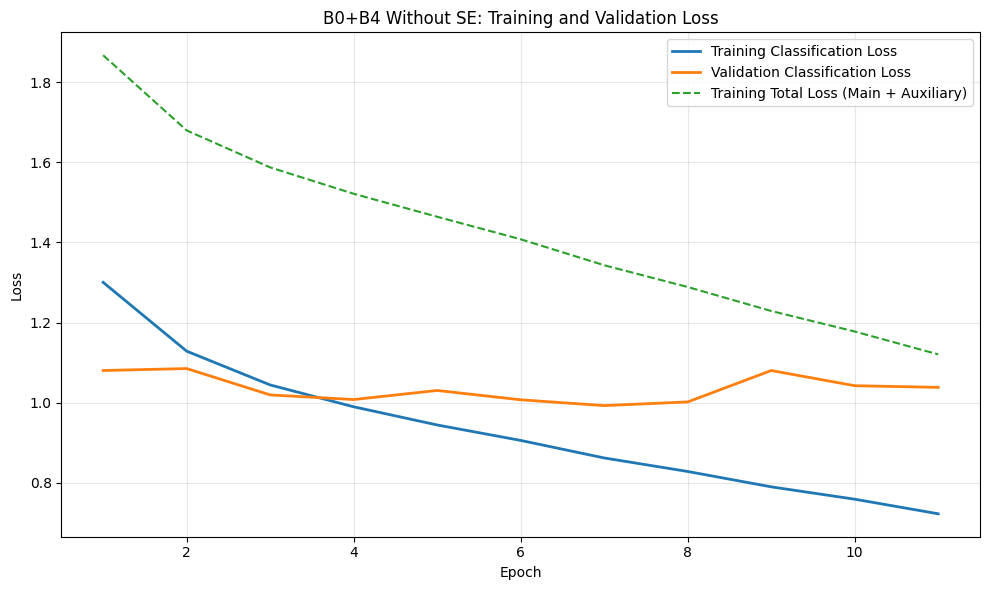

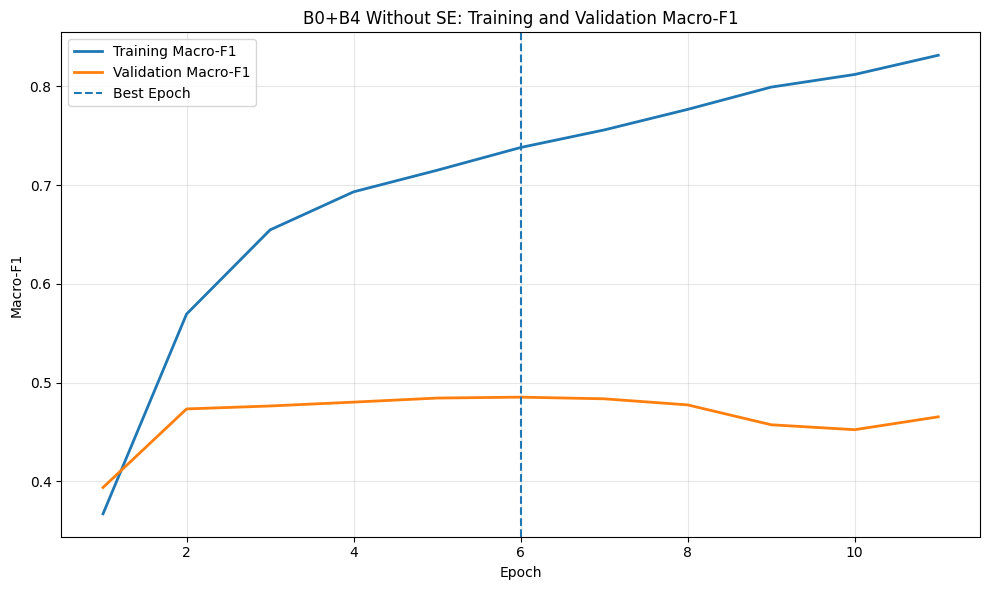

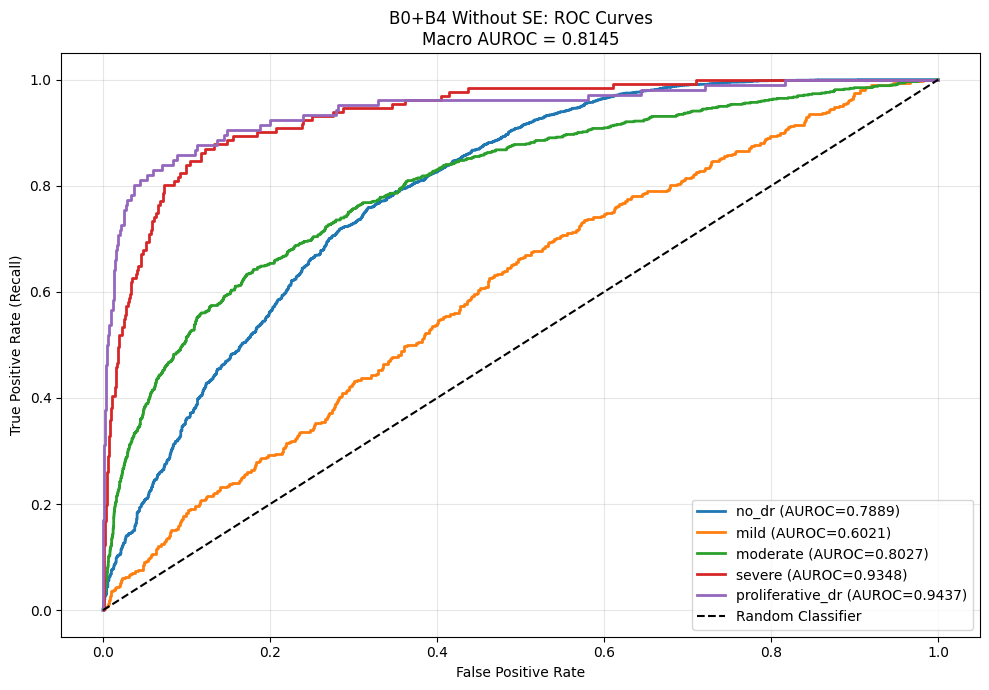

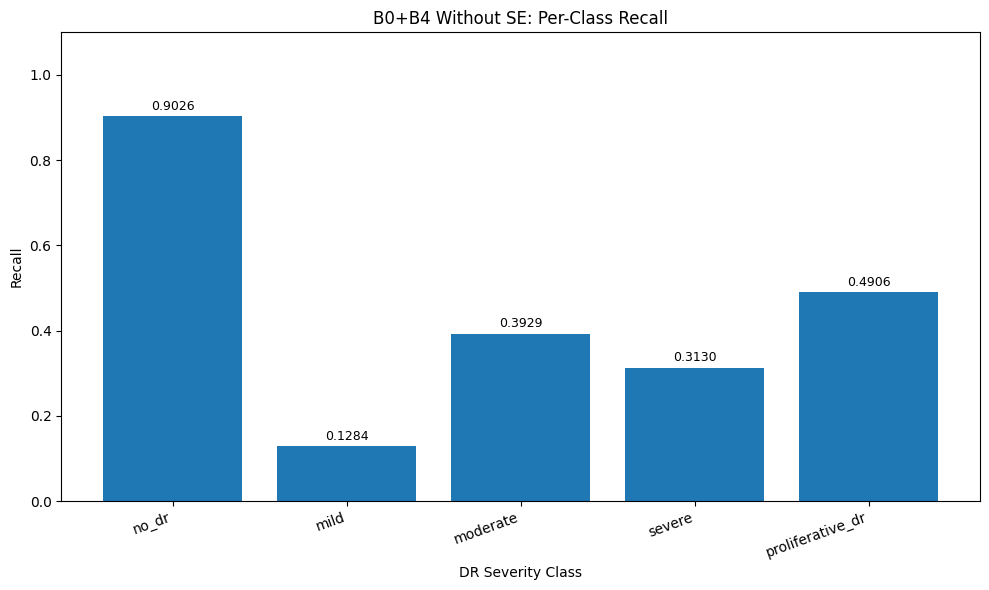

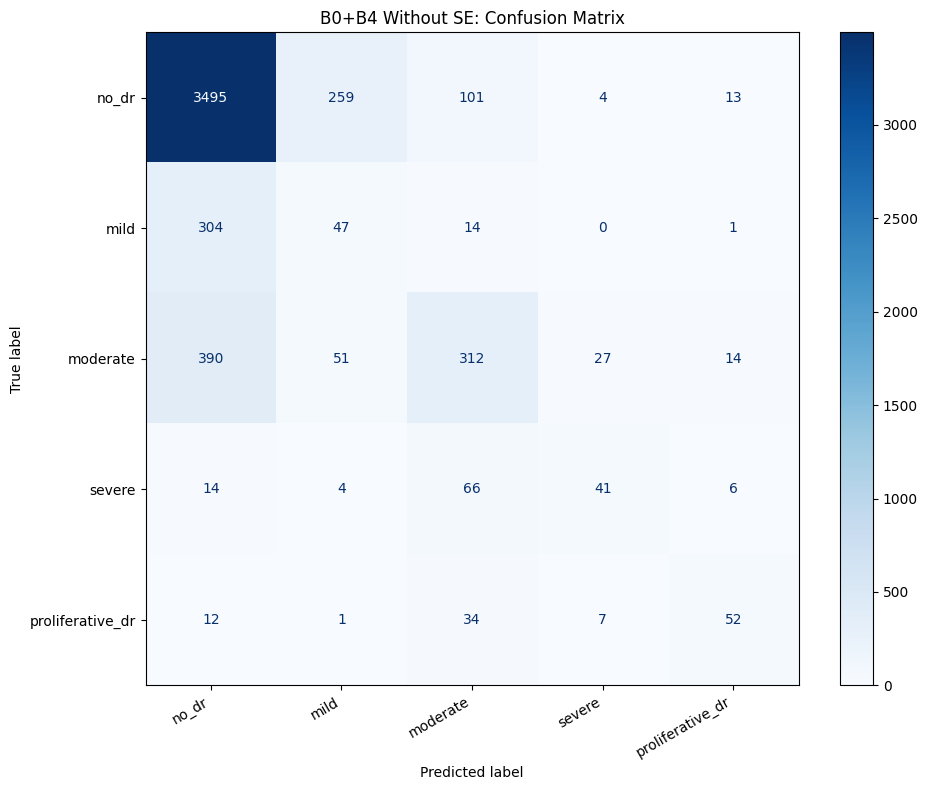


FINAL RESULTS: B0+B4 WITHOUT SE
Accuracy        : 0.7491
Macro Precision : 0.5349
Macro Recall    : 0.4455
Macro F1        : 0.4796
Weighted F1     : 0.7359
Macro AUROC     : 0.8145

All results and graphs saved to:
/content/drive/MyDrive/DR_Project/stage3_ablation_B4_without_SE

TESTING COMPLETED SUCCESSFULLY


In [6]:



import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from tqdm.auto import tqdm

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    auc
)



assert os.path.isfile(NO_SE_CKPT), (
    "Checkpoint not found. Run Cell 5 first."
)

model.load_state_dict(
    torch.load(
        NO_SE_CKPT,
        map_location=device,
        weights_only=True
    )
)

model.eval()

os.makedirs(OUT_DIR, exist_ok=True)

print("=" * 70)
print("B0+B4 WITHOUT SE - FINAL TEST EVALUATION")
print("=" * 70)



y_true = []
y_pred = []
y_probs = []

with torch.inference_mode():

    for rgb, mask, labels in tqdm(
        test_loader,
        desc="Testing B0+B4 without SE"
    ):

        rgb = rgb.to(device)
        mask = mask.to(device)

        if USE_AMP:

            rgb = rgb.contiguous(
                memory_format=torch.channels_last
            )

            mask = mask.contiguous(
                memory_format=torch.channels_last
            )

        with torch.amp.autocast(
            device_type=device.type,
            enabled=USE_AMP
        ):

            logits = model(rgb, mask)

        probs = torch.softmax(
            logits.float(),
            dim=1
        )

        predictions = probs.argmax(dim=1)

        y_true.extend(
            labels.cpu().numpy()
        )

        y_pred.extend(
            predictions.cpu().numpy()
        )

        y_probs.extend(
            probs.cpu().numpy()
        )

y_true = np.asarray(y_true, dtype=int)
y_pred = np.asarray(y_pred, dtype=int)
y_probs = np.asarray(y_probs)

classes = list(range(NUM_CLASSES))



test_accuracy = accuracy_score(
    y_true,
    y_pred
)

macro_precision = precision_score(
    y_true,
    y_pred,
    labels=classes,
    average="macro",
    zero_division=0
)

macro_recall = recall_score(
    y_true,
    y_pred,
    labels=classes,
    average="macro",
    zero_division=0
)

macro_f1 = f1_score(
    y_true,
    y_pred,
    labels=classes,
    average="macro",
    zero_division=0
)

weighted_precision = precision_score(
    y_true,
    y_pred,
    labels=classes,
    average="weighted",
    zero_division=0
)

weighted_recall = recall_score(
    y_true,
    y_pred,
    labels=classes,
    average="weighted",
    zero_division=0
)

weighted_f1 = f1_score(
    y_true,
    y_pred,
    labels=classes,
    average="weighted",
    zero_division=0
)

print("\n" + "=" * 70)
print("OVERALL TEST METRICS")
print("=" * 70)

print(f"Accuracy           : {test_accuracy:.4f}")
print(f"Macro Precision    : {macro_precision:.4f}")
print(f"Macro Recall       : {macro_recall:.4f}")
print(f"Macro F1           : {macro_f1:.4f}")
print(f"Weighted Precision : {weighted_precision:.4f}")
print(f"Weighted Recall    : {weighted_recall:.4f}")
print(f"Weighted F1        : {weighted_f1:.4f}")



report = classification_report(
    y_true,
    y_pred,
    labels=classes,
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0
)

print("\n" + "=" * 70)
print("CLASSIFICATION REPORT")
print("=" * 70)

print(report)

with open(
    os.path.join(
        OUT_DIR,
        "no_SE_classification_report.txt"
    ),
    "w"
) as f:

    f.write(report)



precision_values = precision_score(
    y_true,
    y_pred,
    labels=classes,
    average=None,
    zero_division=0
)

recall_values = recall_score(
    y_true,
    y_pred,
    labels=classes,
    average=None,
    zero_division=0
)

f1_values = f1_score(
    y_true,
    y_pred,
    labels=classes,
    average=None,
    zero_division=0
)

support_values = [
    int(np.sum(y_true == k))
    for k in classes
]

per_class = pd.DataFrame({
    "Class": CLASS_NAMES,
    "Precision": precision_values,
    "Recall": recall_values,
    "F1": f1_values,
    "Support": support_values
})



roc_results = {}
auc_values = []

for k, class_name in enumerate(CLASS_NAMES):

    binary_true = (
        y_true == k
    ).astype(int)

    if len(np.unique(binary_true)) < 2:

        roc_results[class_name] = None
        auc_values.append(np.nan)

        print(
            f"AUROC unavailable for {class_name}"
        )

        continue

    fpr, tpr, thresholds = roc_curve(
        binary_true,
        y_probs[:, k]
    )

    class_auc = auc(fpr, tpr)

    roc_results[class_name] = {
        "fpr": fpr,
        "tpr": tpr,
        "auc": class_auc
    }

    auc_values.append(class_auc)

per_class["AUROC"] = auc_values

if all(np.isfinite(auc_values)):
    macro_auc = float(np.mean(auc_values))
else:
    macro_auc = float("nan")
    print(
        "Macro AUROC unavailable because one or more "
        "classes are missing from the test labels."
    )

print("\n" + "=" * 70)
print("PER-CLASS METRICS")
print("=" * 70)

print(
    per_class.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

print(f"\nMacro AUROC: {macro_auc:.4f}")



summary_df = pd.DataFrame([{
    "Model": "B0+B4 without SE",
    "Accuracy": test_accuracy,
    "Macro Precision": macro_precision,
    "Macro Recall": macro_recall,
    "Macro F1": macro_f1,
    "Weighted Precision": weighted_precision,
    "Weighted Recall": weighted_recall,
    "Weighted F1": weighted_f1,
    "Macro AUROC": macro_auc
}])

summary_df.to_csv(
    os.path.join(
        OUT_DIR,
        "no_SE_test_summary.csv"
    ),
    index=False
)

per_class.to_csv(
    os.path.join(
        OUT_DIR,
        "no_SE_per_class_metrics.csv"
    ),
    index=False,
    float_format="%.6f"
)



history_df = pd.read_csv(
    HISTORY_PATH
)

print("\n" + "=" * 70)
print("TRAINING HISTORY")
print("=" * 70)

print(
    history_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

best_row = history_df.loc[
    history_df["val_macro_f1"].idxmax()
]

print(
    f"\nBest Epoch: {int(best_row['epoch'])}"
)

print(
    f"Best Validation Macro-F1: "
    f"{best_row['val_macro_f1']:.4f}"
)



plt.figure(figsize=(10, 6))

plt.plot(
    history_df["epoch"],
    history_df["train_main_loss"],
    label="Training Classification Loss",
    linewidth=2
)

plt.plot(
    history_df["epoch"],
    history_df["val_loss"],
    label="Validation Classification Loss",
    linewidth=2
)

plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    label="Training Total Loss (Main + Auxiliary)",
    linestyle="--",
    linewidth=1.5
)

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.title(
    "B0+B4 Without SE: Training and Validation Loss"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(
        OUT_DIR,
        "no_SE_loss_curves.png"
    ),
    dpi=200
)

plt.show()



plt.figure(figsize=(10, 6))

plt.plot(
    history_df["epoch"],
    history_df["train_macro_f1"],
    label="Training Macro-F1",
    linewidth=2
)

plt.plot(
    history_df["epoch"],
    history_df["val_macro_f1"],
    label="Validation Macro-F1",
    linewidth=2
)

plt.axvline(
    int(best_row["epoch"]),
    linestyle="--",
    label="Best Epoch"
)

plt.xlabel("Epoch")
plt.ylabel("Macro-F1")

plt.title(
    "B0+B4 Without SE: Training and Validation Macro-F1"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(
        OUT_DIR,
        "no_SE_macro_F1_curves.png"
    ),
    dpi=200
)

plt.show()



plt.figure(figsize=(10, 7))

for class_name in CLASS_NAMES:

    result = roc_results[class_name]

    if result is None:
        continue

    plt.plot(
        result["fpr"],
        result["tpr"],
        linewidth=2,
        label=(
            f"{class_name} "
            f"(AUROC={result['auc']:.4f})"
        )
    )

plt.plot(
    [0, 1],
    [0, 1],
    "k--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")

plt.title(
    "B0+B4 Without SE: ROC Curves\n"
    f"Macro AUROC = {macro_auc:.4f}"
)

plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    os.path.join(
        OUT_DIR,
        "no_SE_AUROC_curves.png"
    ),
    dpi=200
)

plt.show()



plt.figure(figsize=(10, 6))

bars = plt.bar(
    CLASS_NAMES,
    recall_values
)

for bar, value in zip(
    bars,
    recall_values
):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.015,
        f"{value:.4f}",
        ha="center",
        fontsize=9
    )

plt.xlabel("DR Severity Class")
plt.ylabel("Recall")

plt.title(
    "B0+B4 Without SE: Per-Class Recall"
)

plt.ylim(0, 1.10)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()

plt.savefig(
    os.path.join(
        OUT_DIR,
        "no_SE_per_class_recall.png"
    ),
    dpi=200
)

plt.show()



cm = confusion_matrix(
    y_true,
    y_pred,
    labels=classes
)

fig, ax = plt.subplots(
    figsize=(10, 8)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=True
)

plt.setp(
    ax.get_xticklabels(),
    rotation=30,
    ha="right"
)

plt.title(
    "B0+B4 Without SE: Confusion Matrix"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        OUT_DIR,
        "no_SE_confusion_matrix.png"
    ),
    dpi=200
)

plt.show()



predictions_df = pd.DataFrame({
    "Actual": y_true,
    "Predicted": y_pred
})

for k, class_name in enumerate(CLASS_NAMES):

    predictions_df[
        "Probability_" + class_name
    ] = y_probs[:, k]

predictions_df.to_csv(
    os.path.join(
        OUT_DIR,
        "no_SE_test_predictions.csv"
    ),
    index=False
)



print("\n" + "=" * 70)
print("FINAL RESULTS: B0+B4 WITHOUT SE")
print("=" * 70)

print(f"Accuracy        : {test_accuracy:.4f}")
print(f"Macro Precision : {macro_precision:.4f}")
print(f"Macro Recall    : {macro_recall:.4f}")
print(f"Macro F1        : {macro_f1:.4f}")
print(f"Weighted F1     : {weighted_f1:.4f}")
print(f"Macro AUROC     : {macro_auc:.4f}")

print("\nAll results and graphs saved to:")
print(OUT_DIR)

print("\nTESTING COMPLETED SUCCESSFULLY")
